In [1]:

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import xgboost as xgb

from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay
from sklearn.preprocessing import normalize , LabelEncoder
from sklearn.model_selection import train_test_split, KFold

import tensorflow as tf
from tensorflow import keras
from keras.layers import Dense, Flatten, Conv1D, Dropout, MaxPooling1D, Input
from keras.regularizers import l2
from keras.models import Sequential
from keras.callbacks import EarlyStopping
from imblearn.over_sampling import SMOTE

from functions import *

In [2]:
kf = KFold(n_splits=5, shuffle=True, random_state=111)

In [3]:

df = pd.read_csv('https://raw.githubusercontent.com/paq88/Deep-Learning-in-classification-of-common-Carp-intestine-classification/refs/heads/main/Data/Gut_bacteria_merged.csv')
print(df.shape)
print(df.dtypes)
df.head()

(124, 127)
pond                                                                                           object
d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae             float64
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae       float64
d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae                    float64
d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae                    float64
                                                                                               ...   
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae           float64
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae      float64
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae           float64
d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales

,pond,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
0,Gut_S10,2319.0,2187.0,1743.0,500.0,521.0,286.0,366.0,612.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Gut_S10,3391.0,2071.0,355.0,1054.0,1024.0,1952.0,66.0,217.0,95.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Gut_S10,1338.0,7053.0,669.0,279.0,329.0,63.0,52.0,1338.0,139.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Gut_S10,1582.0,15595.0,124.0,503.0,309.0,5.0,3418.0,326.0,76.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Gut_S10,1463.0,3891.0,541.0,7.0,13.0,11.0,61.0,398.0,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df = df.fillna(0)
df.head()

,pond,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
0,Gut_S10,2319.0,2187.0,1743.0,500.0,521.0,286.0,366.0,612.0,160.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Gut_S10,3391.0,2071.0,355.0,1054.0,1024.0,1952.0,66.0,217.0,95.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Gut_S10,1338.0,7053.0,669.0,279.0,329.0,63.0,52.0,1338.0,139.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Gut_S10,1582.0,15595.0,124.0,503.0,309.0,5.0,3418.0,326.0,76.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Gut_S10,1463.0,3891.0,541.0,7.0,13.0,11.0,61.0,398.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
print(df.shape)
df.describe()

(124, 127)


,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
count,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,...,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000
mean,831.653226,8693.169355,171.370968,71.137097,105.548387,196.209677,677.419355,375.854839,53.169355,25.241935,...,0.096774,0.298387,0.080645,2.153226,0.217742,1.604839,0.153226,0.096774,0.266129,0.185484
std,1120.105607,5604.123141,224.484829,146.755443,192.490201,637.902078,2845.964849,456.780652,98.483354,67.552253,...,1.077632,2.270274,0.898027,20.938565,2.093585,13.805159,1.706250,1.077632,2.537872,2.065461
min,0.000000,167.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,106.750000,3913.500000,37.750000,0.000000,0.000000,6.750000,0.000000,55.500000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,469.500000,7454.500000,105.500000,2.000000,13.500000,27.500000,0.000000,211.000000,4.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1037.750000,12774.000000,241.000000,91.500000,131.000000,118.250000,48.750000,467.250000,62.250000,15.250000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,6597.000000,26160.000000,1743.000000,1054.000000,1024.000000,5020.000000,23193.000000,2505.000000,581.000000,539.000000,...,12.000000,23.000000,10.000000,232.000000,23.000000,144.000000,19.000000,12.000000,28.000000,23.000000


In [6]:
predictors = df.columns[1:]
print(len(predictors))

126


## CLR transformation

In [7]:
df[predictors] = pd.DataFrame(clr_manual(df[predictors]),columns = df[predictors].columns)

In [8]:
df.describe()

,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
count,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,...,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000
mean,5.184129,8.149255,3.644067,1.438091,1.940012,2.662686,1.427626,4.205627,1.532341,0.765683,...,-0.609693,-0.572431,-0.611040,-0.531471,-0.591769,-0.557780,-0.606219,-0.609693,-0.584653,-0.604748
std,1.444798,1.072265,1.554761,2.158231,2.209887,1.951443,2.819811,1.903593,1.951759,1.643831,...,0.327155,0.416136,0.319306,0.624163,0.391066,0.584453,0.373966,0.349500,0.417752,0.403019
min,-0.325684,4.708501,-0.436293,-1.245936,-0.858576,-0.859457,-1.472139,-0.656742,-1.245936,-1.245936,...,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104
25%,4.245242,7.605297,3.165891,-0.408017,-0.366712,1.568823,-0.539976,3.359390,-0.374288,-0.452238,...,-0.764629,-0.756155,-0.764629,-0.746398,-0.756155,-0.756155,-0.764629,-0.764629,-0.756155,-0.770888
50%,5.502807,8.190011,3.971892,0.400069,2.041522,2.687662,-0.279643,4.723931,1.130598,-0.307177,...,-0.576803,-0.557009,-0.576803,-0.545442,-0.557009,-0.557009,-0.576803,-0.576803,-0.545442,-0.582855
75%,6.197913,9.010625,4.739503,3.659931,4.141260,4.021147,3.221774,5.387763,3.452128,2.208847,...,-0.401424,-0.395451,-0.401424,-0.389485,-0.399562,-0.399562,-0.401424,-0.401424,-0.395451,-0.401424
max,7.913779,9.793854,6.362286,5.991671,5.983094,7.360192,9.636186,7.295474,5.159305,4.819431,...,1.341129,1.932118,1.174075,4.517037,2.316767,3.730798,2.134445,1.703662,2.742058,2.591176


## resampling 
due to one missing observation (later the shapes wont match during reshape needed for convolution layers)

In [9]:
smote = SMOTE(random_state=111, k_neighbors=3)
X_resampled , y_resampled = smote.fit_resample(df[predictors], df['pond'])
df_resampled = pd.concat([X_resampled, y_resampled], axis=1)

## conversion of class variable


Explanation of pond coding
| number | setup | pond numbers | water supplementation | feed suplementation |
|---|---|---|---|---|
|0|control | 8,14,18,24,29|NO|NO|
|1|set 1 | 12,16,19,23,26|Em farma|NO|
|2|set 2 | 10,21,28,30,32|Em farma|EM|
|3|set 3 | 9,13,17,20,27|EM|NO|
|4|set 4 | 11,15,22,25,31|EM|EM|

In [10]:
df = df_resampled.copy()
codes = {0 : [8,14,18,24,29], 1: [12,16,19,23,26], 2 : [10,21,28,30,32], 3 : [9,13,17,20,27], 4 : [11,15,22,25,31]}
codes3 = {0 : [8,14,18,24,29], 1: [12,16,19,23,26,9,13,17,20,27], 2 : [10,21,28,30,32,11,15,22,25,31]}
codes2 = {0 : [8,14,18,24,29,12,16,19,23,26,9,13,17,20,27], 1 : [10,21,28,30,32,11,15,22,25,31]}

df['pond_5'] = df['pond'].apply(lambda x: pond_decoder(x,codes))
df['pond_3'] = df['pond'].apply(lambda x: pond_decoder(x,codes3))
df['pond_2'] = df['pond'].apply(lambda x: pond_decoder(x,codes2))
df = df.copy()

## Splitting data into train and test sets

# 5 Class

In [47]:
target = 'pond_5'
df_val_train, df_test = train_test_split(df, test_size=0.2, random_state=111, stratify=df[target])
X_train = df_val_train[predictors].values.reshape(-1, len(predictors), 1)
X_test = df_test[predictors].values.reshape(-1, len(predictors), 1)

y_train = df_val_train[target].values
y_train = keras.utils.to_categorical(y_train, num_classes=max(df[target])+1)
y_test = df_test[target].values
y_test = keras.utils.to_categorical(y_test, num_classes=max(df[target])+1)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(100, 126, 1) (100, 5) (25, 126, 1) (25, 5)


## C-DNN

### Model building


In [12]:
input_data = Input(shape=(126,1))
conv_output = Conv1D(filters=2, kernel_size=25, activation='relu', input_shape=(126,1), kernel_regularizer=keras.regularizers.l2(0.01))(input_data)
conv_output = Conv1D(filters=1, kernel_size=4, activation='relu', kernel_regularizer=l2(0.01))(conv_output)
conv_features = MaxPooling1D(pool_size=4)(conv_output)
output = Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01))(conv_features)
output = Flatten()(output)
output = Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01))(output)
output = Dropout(rate=0.25)(output)
output = Dense(16, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01))(output)
output = Dense(5, activation='softmax')(output)


model5_c = keras.Model(inputs=input_data, outputs=output)
optimizer = keras.optimizers.Adam(learning_rate=0.001)
model5_c.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
model5_c.summary()

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 126, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 102, 2)         │            52 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 99, 1)          │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 24, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 24, 64)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │        49,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,986 (195.26 KB)

 Trainable params: 49,986 (195.26 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation 

Number of classes: 5
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - accuracy: 0.5000 - loss: 2.7128
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
predicted classes:       [1 1 1 1 0 4 2 0 0 3 3 4 3 4 0 4 3 4 0 0]
true validation classes: [2 1 1 0 2 4 2 4 0 1 1 4 3 3 0 4 3 1 2 4]
mean confidence score: 21207.6797, sd confidence score: 90479.3276
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6000 - loss: 2.7607
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
predicted classes:       [2 2 0 2 2 0 3 3 3 2 2 0 1 1 0 2 2 4 2 2]
true validation classes: [4 2 0 0 1 0 3 1 3 3 2 1 4 4 0 2 2 4 2 2]
mean confidence score: 13736.9153, sd confidence score: 33482.2383
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.4500 - loss: 3.5714
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
predicted classes:       [0 4 4 3 2 4 4 4 2 0 0 3 3 1 0 3 0 3 2 1]
true validation classes: [4 0 4 3 2 3 0 4 2 1 0 1 3 4 2 1 3 1 2 1]
mean confidence score: 295.8041, sd confidence

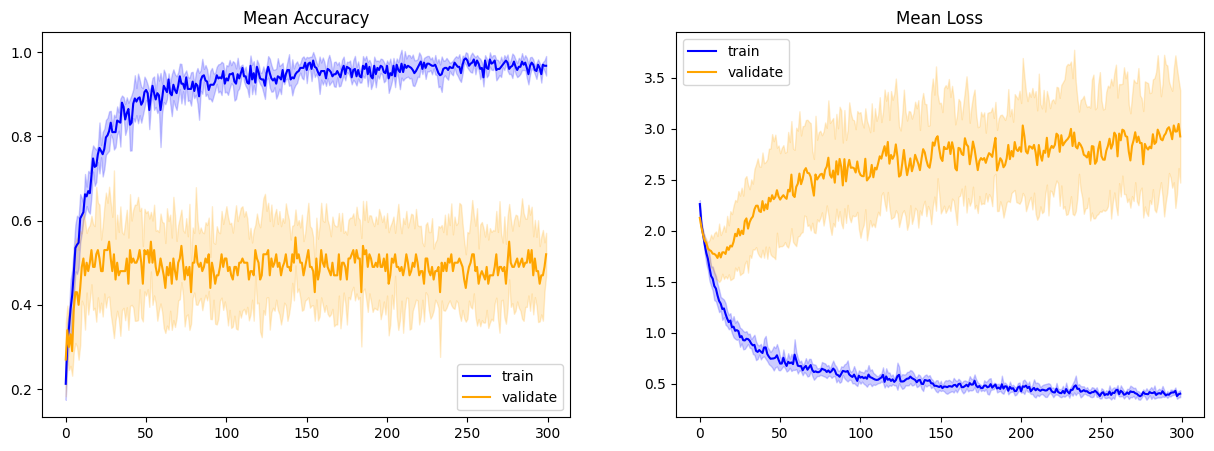

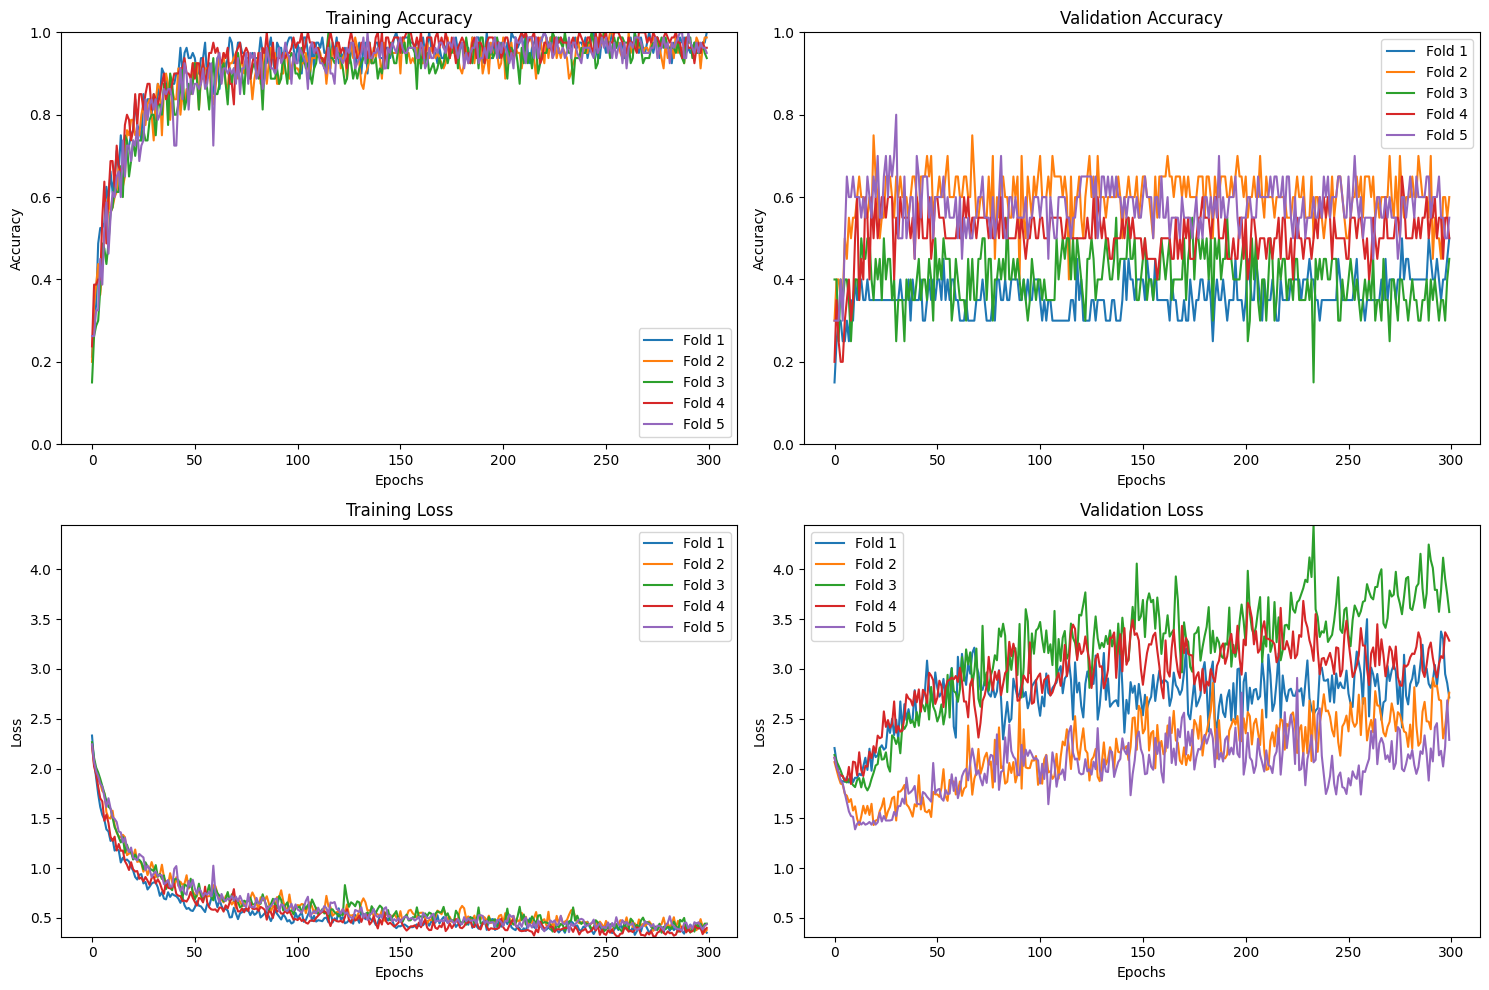

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
predicted classes:       [2 3 3 4 2 4 1 3 1 4 1 0 2 4 1 0 1 1 0 3]
true validation classes: [1 3 2 0 2 4 0 3 0 4 0 3 2 4 1 1 3 1 0 3]


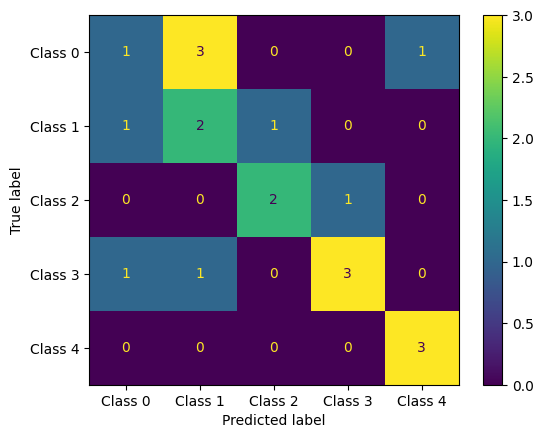

In [13]:
mean_acc_DNN_5_val, sd_acc_DNN_5_val =  crossvalidate(df_val_train, model5_c, predictors, target ,kf,300,True)

### testing 

Epoch 1/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.2357 - loss: 2.2427 - val_accuracy: 0.3600 - val_loss: 2.0055
Epoch 2/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2794 - loss: 1.9763 - val_accuracy: 0.4800 - val_loss: 1.9168
Epoch 3/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3705 - loss: 1.8560 - val_accuracy: 0.4000 - val_loss: 1.8468
Epoch 4/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3897 - loss: 1.7802 - val_accuracy: 0.5600 - val_loss: 1.7931
Epoch 5/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3796 - loss: 1.7449 - val_accuracy: 0.6000 - val_loss: 1.7135
Epoch 6/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4802 - loss: 1.5886 - val_accuracy: 0.6400 - val_loss: 1.6720
Epoch 7/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6331 - loss: 1.4252 - val_accuracy: 0.6000 - val_loss: 1.5944
Epoch 8/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4987 - loss: 1.5346 - val_accuracy: 0.6000 - v

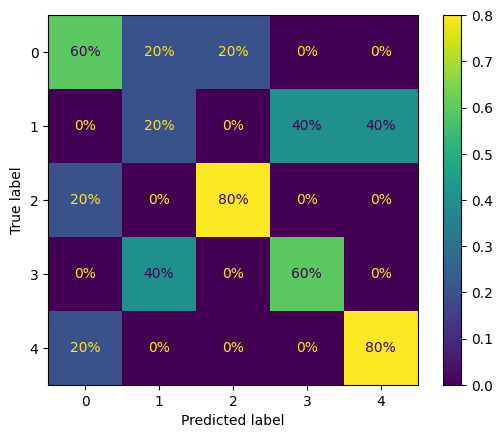

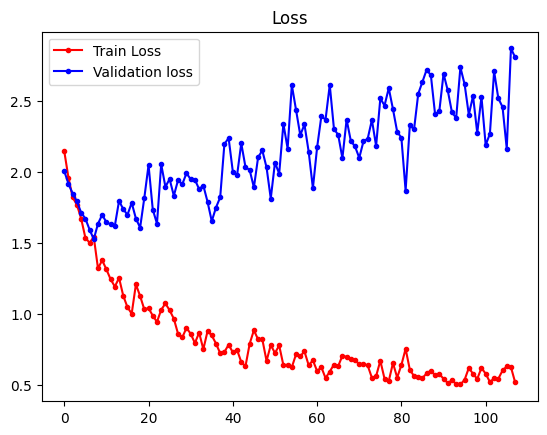

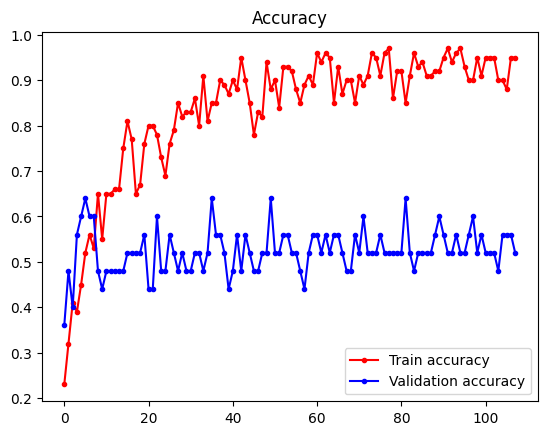

In [14]:
reset_weights(model5_c)
history1=model5_c.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, batch_size = 3, validation_data = (X_test, y_test), 
                      callbacks = [EarlyStopping(monitor='val_loss', patience=100, restore_best_weights=True)])
acc_5_DNN_test = evaluate_model(model5_c, history1, X_test, y_test)

## XGB

In [15]:
feature_extractor_5_c = keras.Model(
    inputs=model5_c.input,
    outputs=Flatten()(model5_c.get_layer("max_pooling1d").output)
)


conv_data_test = feature_extractor_5_c.predict(X_test)
conv_data_train = feature_extractor_5_c.predict(X_train)

xgb_df_test = pd.DataFrame(conv_data_test)
column_names = xgb_df_test.columns.tolist()
column_names = [str(i) for i in column_names]
xgb_df_test.columns = column_names
xgb_df_test[target] = df_test[target].values

xgb_df_train = pd.DataFrame(conv_data_train)
xgb_df_train.columns = column_names
xgb_df_train[target] = df_val_train[target].values


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


In [16]:
xgb_df_test

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,pond_5
0,0.693900,1.927910,0.275219,0.474386,1.045187,1.387812,0.015204,0.357933,1.208218,0.799587,...,1.701344,0.713899,1.068783,1.368978,1.347076,2.096280,1.328405,0.074357,0.518652,0
1,0.964649,0.653716,0.116243,0.503176,1.076270,1.164415,0.175940,0.910923,1.289471,1.673621,...,0.661703,1.133232,1.121748,0.877651,0.191982,0.000000,0.000000,0.000000,0.000000,0
2,0.555081,0.202844,0.707080,0.409173,0.959550,1.162795,0.000000,0.487456,1.215708,1.010274,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3
3,0.264479,0.173833,0.168240,0.491151,0.212882,0.320591,0.529111,0.969391,0.889187,0.601805,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4
4,0.871893,0.090895,1.042786,0.234645,0.052119,0.694699,0.581556,0.948972,0.668984,0.189012,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1
5,1.403181,0.324404,0.235762,0.364579,0.301432,1.106058,0.166162,0.618934,1.491886,0.990734,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3
6,0.042202,0.818075,0.350790,1.945690,0.720676,1.905899,0.000000,1.086790,0.775454,1.059865,...,0.075779,0.987155,1.071084,1.411238,0.141220,0.023317,0.000000,0.000000,0.000000,2
7,0.214508,0.205976,0.309348,0.834768,1.439313,1.652044,0.228907,0.323671,2.045377,0.345818,...,0.207016,0.285413,0.000000,0.619012,1.279613,1.416281,0.871800,0.201338,0.000000,1
8,2.292675,0.698844,0.156947,0.250561,0.924785,1.030385,0.124724,0.945439,1.486188,1.378359,...,0.543739,0.658408,0.579102,0.137566,0.000000,0.000000,0.000000,0.000000,0.000000,1
9,0.763872,0.843920,0.114143,2.342094,0.614362,0.578017,1.807678,1.293728,1.143687,0.132517,...,0.384880,0.148452,0.000000,0.000000,0.000000,0.035956,0.362987,0.000000,0.171946,2


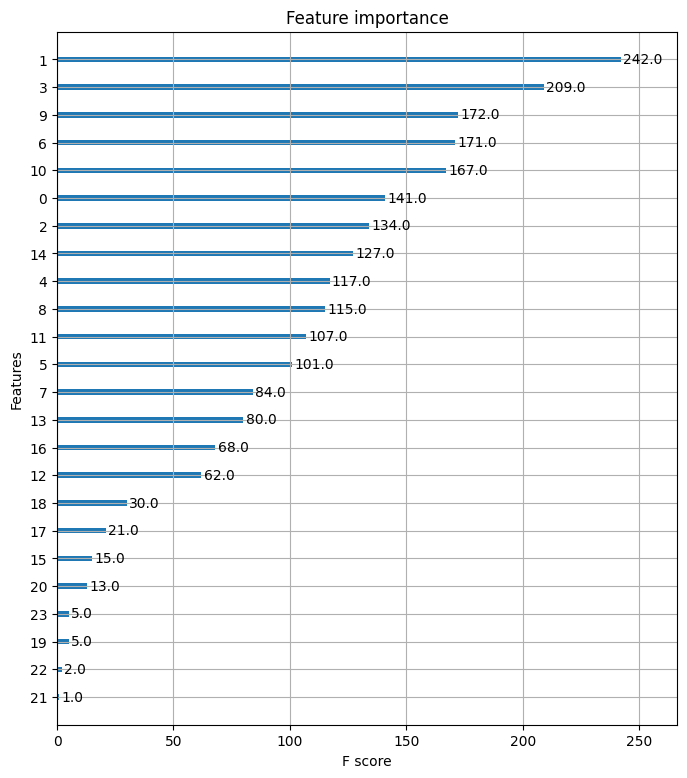

Accuracy0.56
true: [0 0 3 4 1 3 2 1 1 2 3 3 2 4 0 2 1 4 0 2 4 0 1 3 4]
predicted: [2. 0. 1. 4. 3. 1. 0. 0. 3. 2. 3. 3. 2. 0. 2. 2. 1. 4. 1. 2. 4. 0. 1. 1.
 4.]


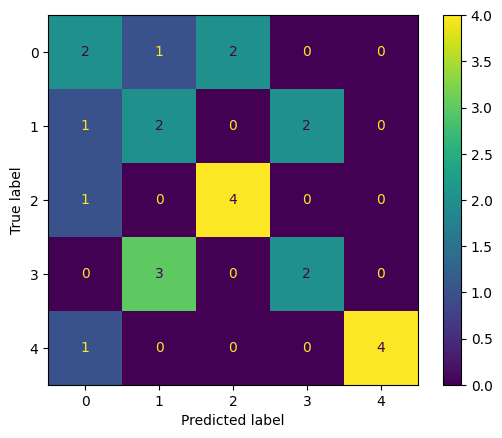

In [17]:
dtrain = xgb.DMatrix(xgb_df_train[column_names].values, label=xgb_df_train[target].values, feature_names=column_names)  
dtest = xgb.DMatrix(xgb_df_test[column_names].values, label=xgb_df_test[target].values, feature_names=column_names)
params = {
    'objective': 'multi:softmax',
    'num_class': 5,
    'max_depth': 3, 
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)

fig, ax = plt.subplots(figsize=(8, 9))  
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")
acc_XGB_5_test = xgb_acc
cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

## C-SNN

In [48]:
model5_c_s = Sequential([
    Conv1D(filters=2, kernel_size=25, activation='relu', input_shape=(126,1), kernel_regularizer=keras.regularizers.l2(0.01)),
    Conv1D(filters=1, kernel_size=4, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01)),
    MaxPooling1D(pool_size=4),
    Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01)),
    Flatten(),
    Dropout(rate=0.25),
    Dense(5, activation='softmax')
])
model5_c_s.summary()
loss = "categorical_crossentropy"
metrics = ["accuracy"]
optimizer = keras.optimizers.Adam(learning_rate = 0.0001)
model5_c_s.compile(optimizer = optimizer, loss = loss, metrics=metrics)

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_14 (Conv1D)              │ (None, 102, 2)         │            52 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_15 (Conv1D)              │ (None, 99, 1)          │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 24, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 24, 64)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 5)              │         7,685 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,874 (30.76 KB)

 Trainable params: 7,874 (30.76 KB)

 Non-trainable params: 0 (0.00 B)

Number of classes: 5
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.3000 - loss: 1.6051
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
predicted classes:       [1 3 4 4 3 3 2 4 0 3 4 2 2 4 0 2 3 4 2 3]
true validation classes: [2 1 1 0 2 4 2 4 0 1 1 4 3 3 0 4 3 1 2 4]
mean confidence score: 12.6222, sd confidence score: 22.8957
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6000 - loss: 1.2237
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
predicted classes:       [4 2 0 2 4 0 3 1 4 2 0 0 3 2 0 2 2 4 2 2]
true validation classes: [4 2 0 0 1 0 3 1 3 3 2 1 4 4 0 2 2 4 2 2]
mean confidence score: 3.7565, sd confidence score: 4.0785
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.4000 - loss: 1.5826
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
predicted classes:       [0 4 0 3 4 0 4 4 2 1 0 1 3 3 1 3 0 3 4 1]
true validation classes: [4 0 4 3 2 3 0 4 2 1 0 1 3 4 2 1 3 1 2 1]
mean confidence score: 20.6246, sd confidence score: 67.8519

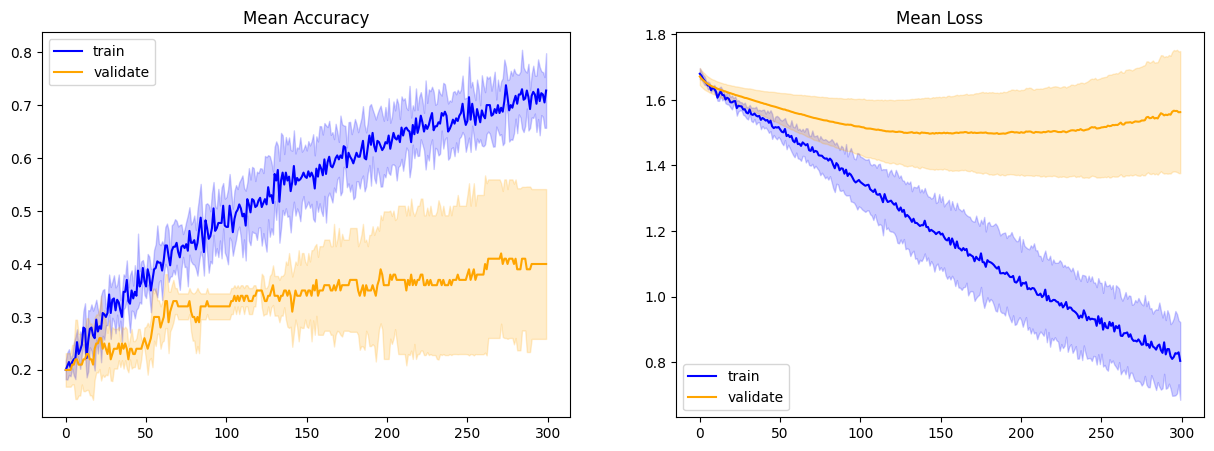

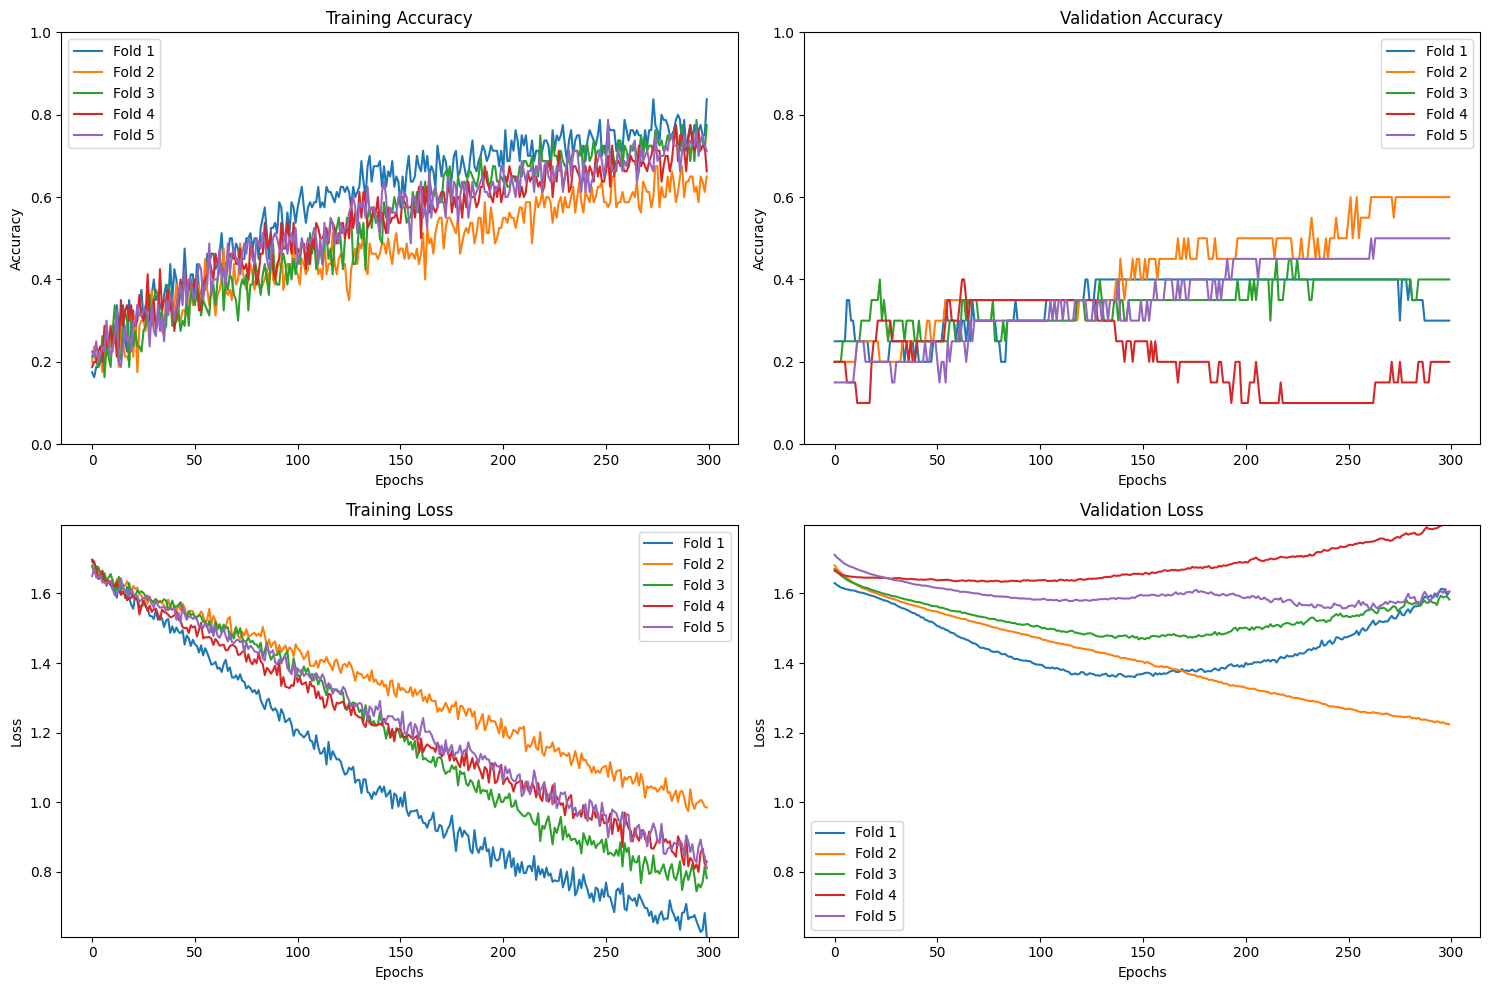

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
predicted classes:       [4 1 2 4 2 4 1 3 1 1 0 0 2 2 1 1 1 1 1 3]
true validation classes: [1 3 2 0 2 4 0 3 0 4 0 3 2 4 1 1 3 1 0 3]


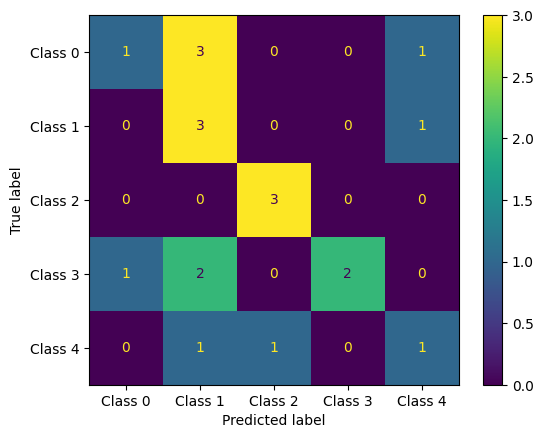

In [49]:
reset_weights(model5_c_s)
mean_acc_SNN_5_val, sd_acc_SNN_5_val =  crossvalidate(df_val_train, model5_c_s, predictors, 'pond_5',kf,300,True)

Epoch 1/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.1941 - loss: 1.6751 - val_accuracy: 0.2000 - val_loss: 1.6421
Epoch 2/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2105 - loss: 1.6593 - val_accuracy: 0.2000 - val_loss: 1.6347
Epoch 3/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2330 - loss: 1.6341 - val_accuracy: 0.2000 - val_loss: 1.6296
Epoch 4/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1710 - loss: 1.6491 - val_accuracy: 0.2000 - val_loss: 1.6248
Epoch 5/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2178 - loss: 1.6584 - val_accuracy: 0.2000 - val_loss: 1.6207
Epoch 6/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2865 - loss: 1.6167 - val_accuracy: 0.1600 - val_loss: 1.6168
Epoch 7/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1997 - loss: 1.6448 - val_accuracy: 0.1600 - val_loss: 1.6134
Epoch 8/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3245 - loss: 1.5873 - val_accuracy: 0.1600 - v

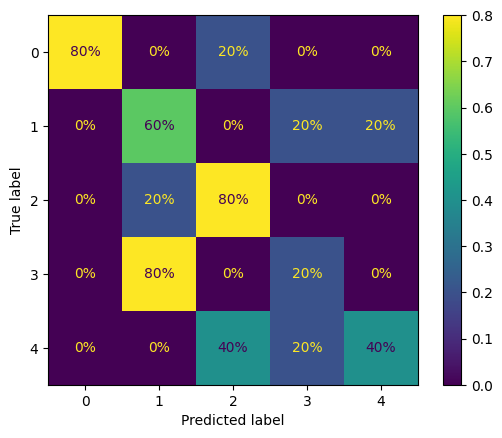

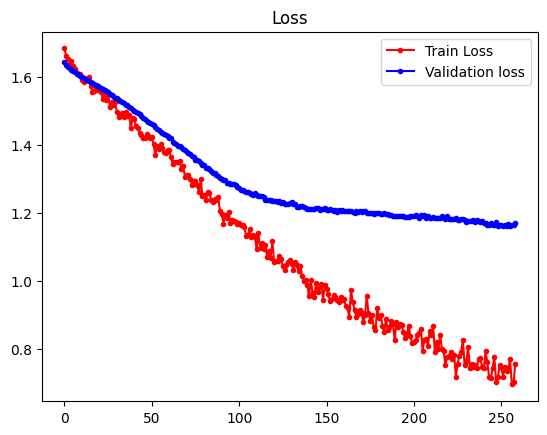

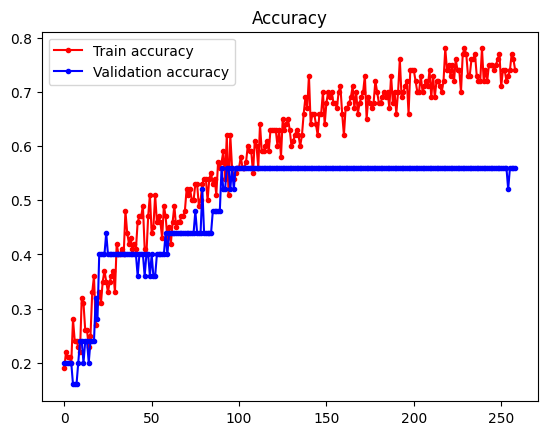

In [50]:

reset_weights(model5_c_s)
history1_s=model5_c_s.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, batch_size = 3, validation_data = (X_test, y_test), callbacks = [EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
acc_5_SNN_test = evaluate_model(model5_c_s, history1_s, X_test, y_test)

# 3 Class


## C-DNN

In [51]:
target = 'pond_3'
df_val_train, df_test = train_test_split(df, test_size=0.2, random_state=111, stratify=df[target])
X_train = df_val_train[predictors].values.reshape(-1, len(predictors), 1)
X_test = df_test[predictors].values.reshape(-1, len(predictors), 1)

y_train = df_val_train[target].values
y_train = keras.utils.to_categorical(y_train, num_classes=max(df[target])+1)
y_test = df_test[target].values
y_test = keras.utils.to_categorical(y_test, num_classes=max(df[target])+1)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(100, 126, 1) (100, 3) (25, 126, 1) (25, 3)


In [22]:
input_data = Input(shape=(126,1))
conv_output = Conv1D(filters=2, kernel_size=25, activation='relu', input_shape=(126,1), kernel_regularizer=keras.regularizers.l2(0.01))(input_data)
conv_output = Conv1D(filters=1, kernel_size=4, activation='relu', kernel_regularizer=l2(0.01))(conv_output)
conv_features = MaxPooling1D(pool_size=4)(conv_output)
output = Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01))(conv_features)
output = Flatten()(output)
output = Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01))(output)
output = Dropout(rate=0.25)(output)
output = Dense(16, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01))(output)
output = Dense(3, activation='softmax')(output)


model3_c = keras.Model(inputs=input_data, outputs=output)
optimizer = keras.optimizers.Adam(learning_rate=0.001)
model3_c.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
model3_c.summary()

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 126, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 102, 2)         │            52 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 99, 1)          │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 24, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 24, 64)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │        49,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,952 (195.12 KB)

 Trainable params: 49,952 (195.12 KB)

 Non-trainable params: 0 (0.00 B)

Number of classes: 3
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.7000 - loss: 2.0008
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
predicted classes:       [0 2 2 2 2 1 2 0 1 0 0 1 0 1 1 2 1 1 1 1]
true validation classes: [2 1 2 2 2 1 2 0 2 0 1 1 1 1 1 2 2 1 1 1]
mean confidence score: 348068.0621, sd confidence score: 1508171.9358
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7000 - loss: 1.0872
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
predicted classes:       [0 0 2 1 1 2 2 1 0 2 1 0 0 1 1 0 2 2 1 1]
true validation classes: [0 0 1 2 2 2 2 1 0 1 1 0 0 1 1 2 1 2 1 1]
mean confidence score: 115095844.8015, sd confidence score: 501547467.7872
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7500 - loss: 1.8746
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
predicted classes:       [1 2 2 0 2 2 1 2 1 2 1 1 1 2 0 1 0 2 2 2]
true validation classes: [1 2 0 0 2 2 1 0 1 2 1 1 1 2 1 2 2 2 2 2]
mean confidence score: 50992.8608, 

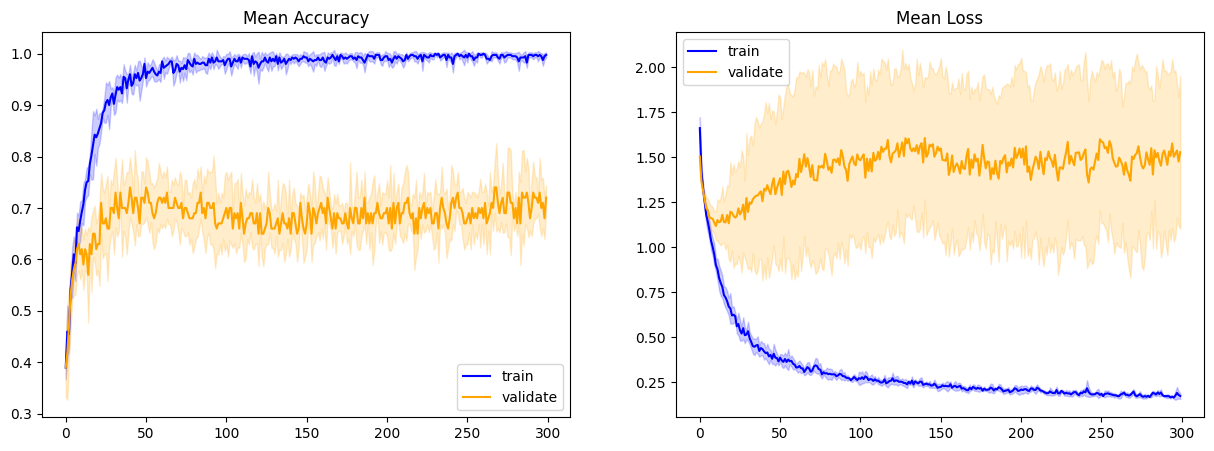

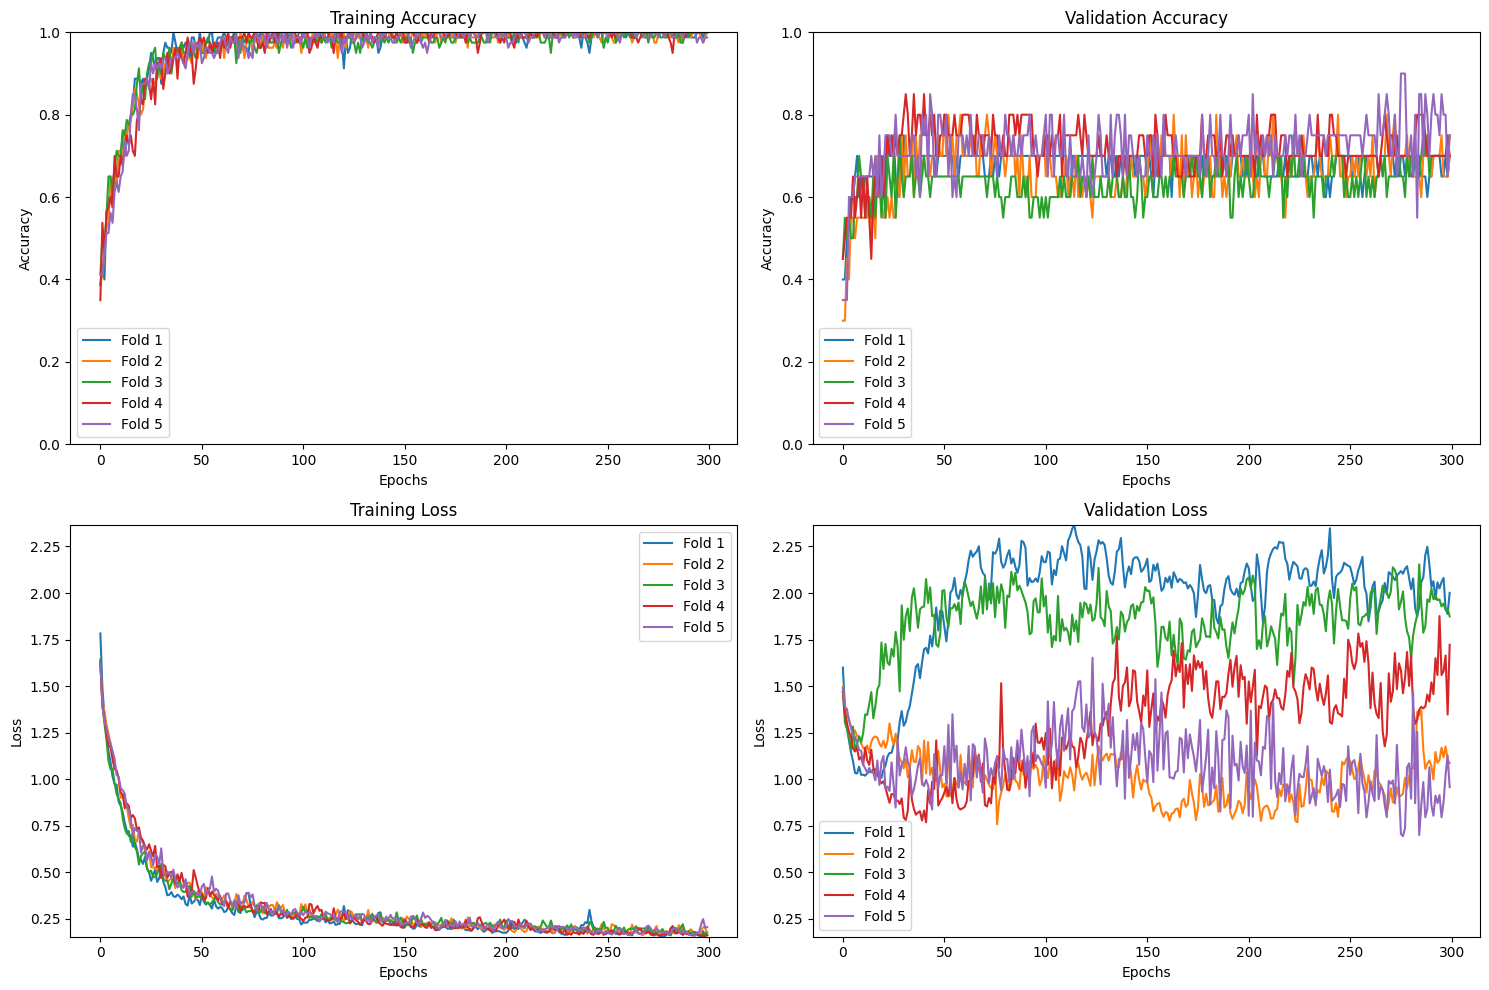

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
predicted classes:       [1 1 0 2 1 1 2 0 0 1 1 1 2 1 2 0 1 0 1 1]
true validation classes: [0 1 0 2 1 1 2 0 2 1 2 2 2 1 2 0 0 0 1 1]


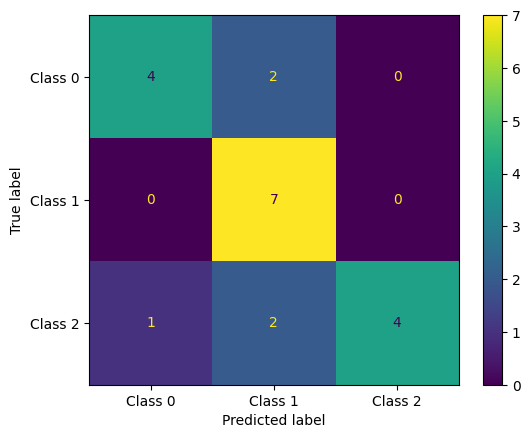

In [23]:
mean_acc_DNN_3_val, sd_acc_DNN_3_val = crossvalidate(df_val_train, model3_c, predictors, 'pond_3',kf,300,True)

In [42]:
reset_weights(model3_c)
history2=model3_c.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, batch_size = 3, validation_data = (X_test, y_test), callbacks = [EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
acc_3_DNN_test = evaluate_model(model3_c, history1, X_test, y_test)

Epoch 1/500


InvalidArgumentError: Graph execution error:

Detected at node compile_loss/categorical_crossentropy/softmax_cross_entropy_with_logits defined at (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>

  File "C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance

  File "C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\ipykernel\kernelapp.py", line 739, in start

  File "C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Py

## XGB

In [25]:
feature_extractor_3_c = keras.Model(
    inputs=model3_c.input,
    outputs=Flatten()(model3_c.get_layer("max_pooling1d_2").output)
)


conv_data_test = feature_extractor_3_c.predict(X_test)
conv_data_train = feature_extractor_3_c.predict(X_train)
print(conv_data_test.shape, conv_data_train.shape)
xgb_df_test = pd.DataFrame(conv_data_test)
column_names = xgb_df_test.columns.tolist()
column_names = [str(i) for i in column_names]
xgb_df_test.columns = column_names
xgb_df_test[target] = df_test[target].values

xgb_df_train = pd.DataFrame(conv_data_train)
xgb_df_train.columns = column_names
xgb_df_train[target] = df_val_train[target].values


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
(25, 24) (100, 24)


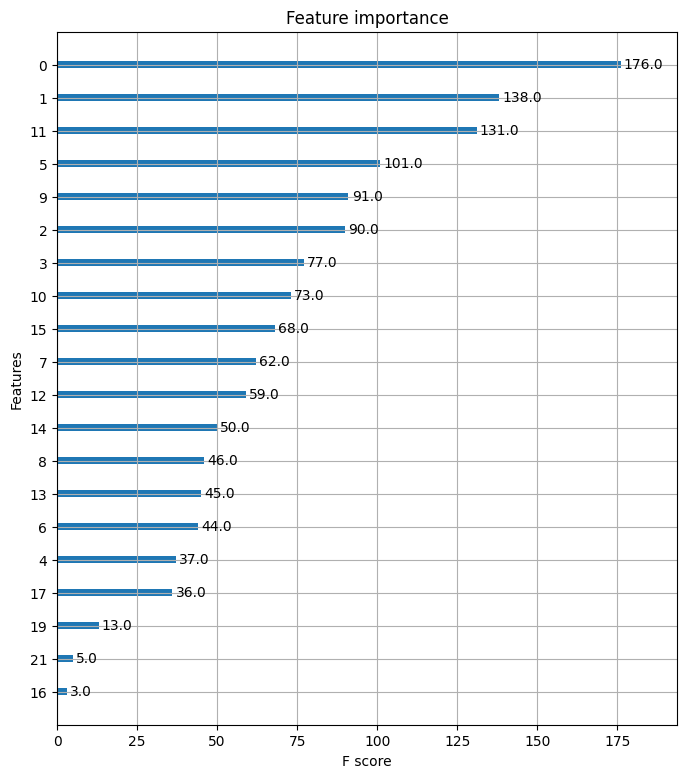

Accuracy0.64
true: [2 2 2 0 2 2 2 2 0 1 2 1 1 1 1 1 1 0 2 2 0 0 1 1 1]
predicted: [0. 2. 2. 0. 2. 2. 1. 1. 2. 1. 2. 2. 1. 1. 1. 1. 0. 1. 2. 2. 0. 2. 2. 1.
 1.]


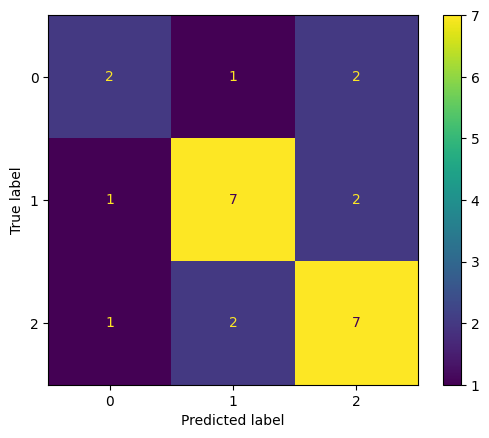

In [26]:
dtrain = xgb.DMatrix(xgb_df_train[column_names].values, label=xgb_df_train[target].values, feature_names=column_names)  
dtest = xgb.DMatrix(xgb_df_test[column_names].values, label=xgb_df_test[target].values, feature_names=column_names)
params = {
    'objective': 'multi:softmax',
    'num_class': 3,
    'max_depth': 3, 
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)

fig, ax = plt.subplots(figsize=(8, 9))  
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")
acc_XGB_3_test = xgb_acc
cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

## C-SNN

In [52]:
model3_c_s = Sequential([
    Conv1D(filters=2, kernel_size=25, activation='relu', input_shape=(126,1), kernel_regularizer=keras.regularizers.l2(0.01)),
    Conv1D(filters=1, kernel_size=4, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01)),
    MaxPooling1D(pool_size=4),
    Flatten(),
    Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01)),
    Dropout(rate=0.25),
    Dense(3, activation='softmax')
])
model3_c_s.summary()
loss = "categorical_crossentropy"
metrics = ["accuracy"]
optimizer = keras.optimizers.Adam(learning_rate = 0.0001)
model3_c_s.compile(optimizer = optimizer, loss = loss, metrics=metrics)

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_16 (Conv1D)              │ (None, 102, 2)         │            52 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_17 (Conv1D)              │ (None, 99, 1)          │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_8 (MaxPooling1D)  │ (None, 24, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 64)             │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,856 (7.25 KB)

 Trainable params: 1,856 (7.25 KB)

 Non-trainable params: 0 (0.00 B)

Number of classes: 3
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.7500 - loss: 0.6806
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
predicted classes:       [2 1 2 2 0 1 2 1 2 0 2 1 0 1 1 2 2 1 2 1]
true validation classes: [2 1 2 2 2 1 2 0 2 0 1 1 1 1 1 2 2 1 1 1]
mean confidence score: 16.7762, sd confidence score: 21.2958
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5500 - loss: 1.0646
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
predicted classes:       [0 0 2 2 2 1 2 0 0 2 1 1 1 1 1 2 2 1 1 0]
true validation classes: [0 0 1 2 2 2 2 1 0 1 1 0 0 1 1 2 1 2 1 1]
mean confidence score: 7.0831, sd confidence score: 9.6862
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4500 - loss: 1.6055
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
predicted classes:       [1 2 2 2 2 1 1 1 2 2 2 2 2 2 0 2 0 2 1 2]
true validation classes: [1 2 0 0 2 2 1 0 1 2 1 1 1 2 1 2 2 2 2 2]
mean confidence score: 20.4486, sd confidence score: 38.5717

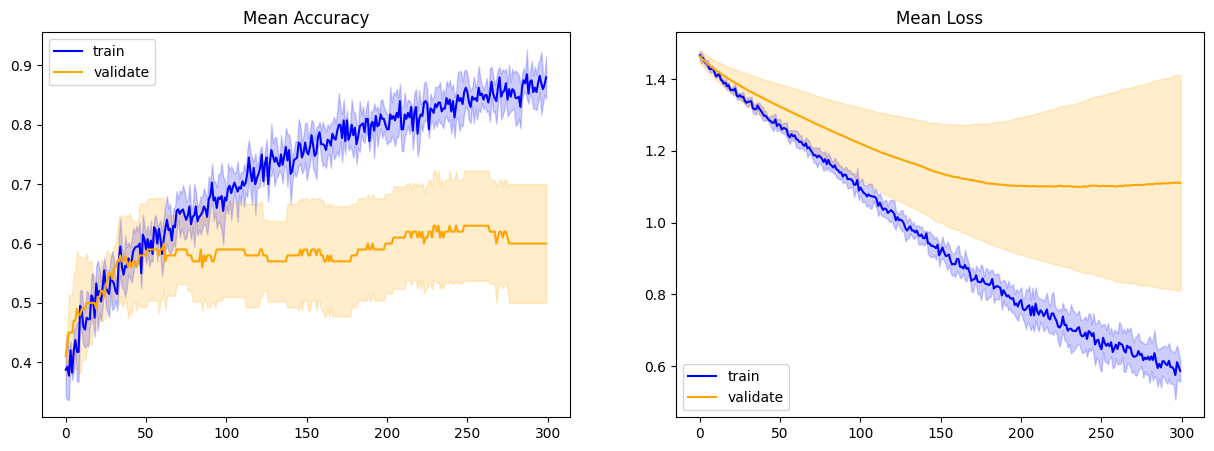

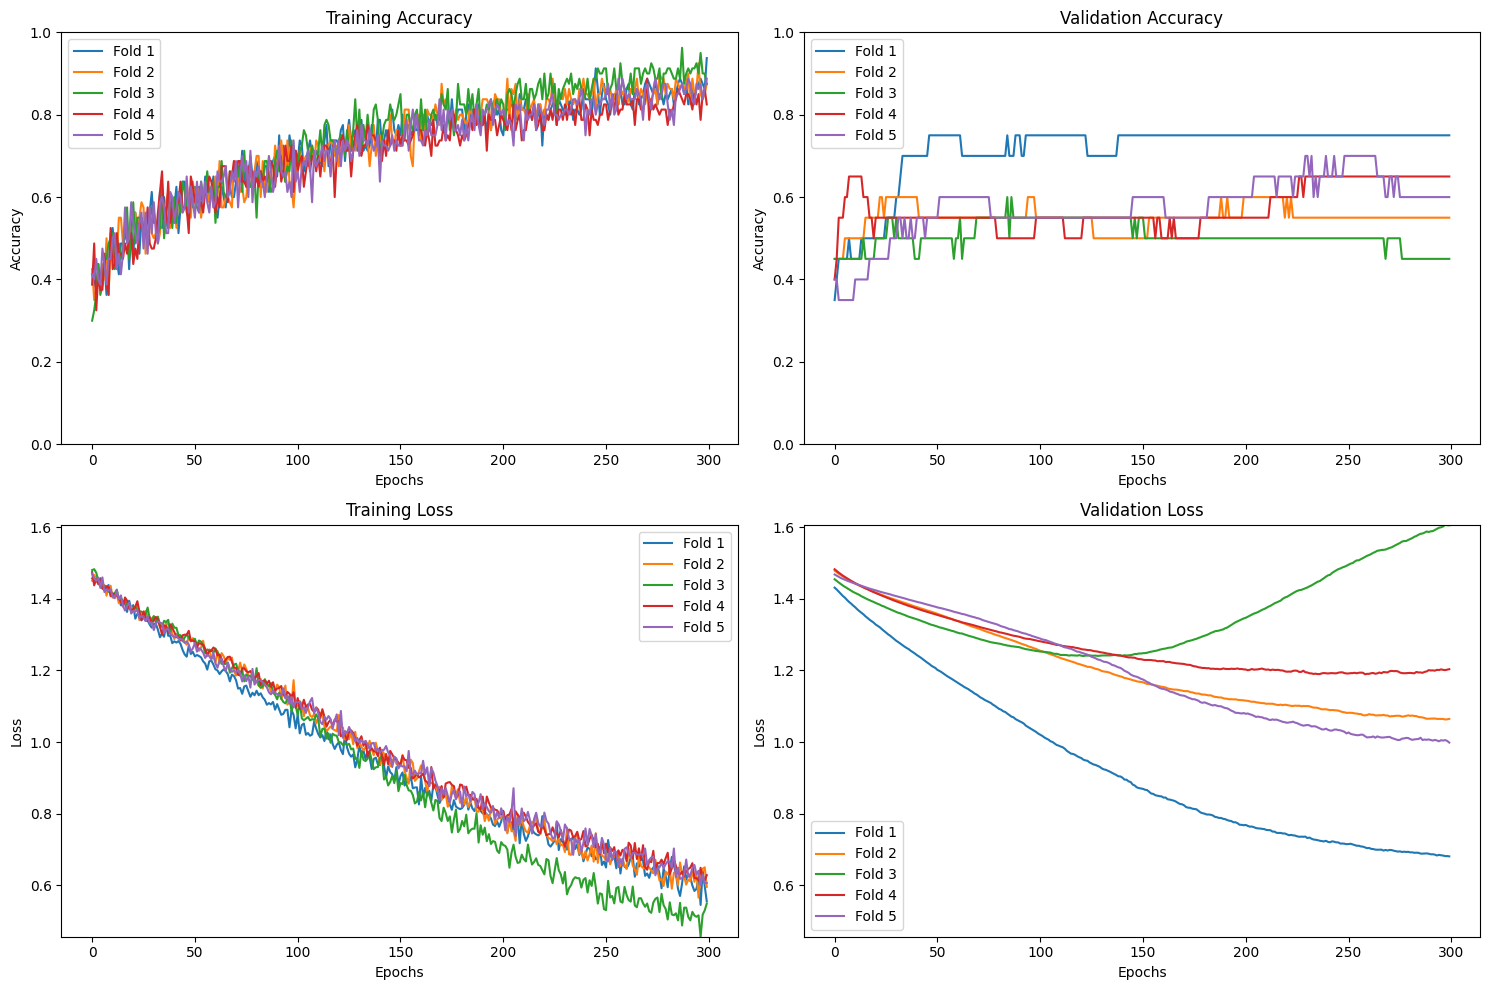

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
predicted classes:       [0 1 1 1 1 1 2 1 1 1 2 2 2 1 2 1 1 1 1 2]
true validation classes: [0 1 0 2 1 1 2 0 2 1 2 2 2 1 2 0 0 0 1 1]


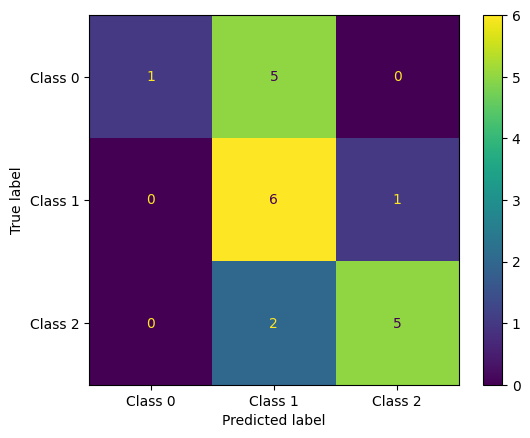

In [53]:
mean_acc_SNN_3_val, sd_acc_SNN_3_val = crossvalidate(df_val_train, model3_c_s, predictors, 'pond_3',kf,300,True)

Epoch 1/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3016 - loss: 1.4873 - val_accuracy: 0.3600 - val_loss: 1.4857
Epoch 2/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3971 - loss: 1.4735 - val_accuracy: 0.4000 - val_loss: 1.4770
Epoch 3/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4461 - loss: 1.4415 - val_accuracy: 0.4000 - val_loss: 1.4693
Epoch 4/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3925 - loss: 1.4504 - val_accuracy: 0.4000 - val_loss: 1.4611
Epoch 5/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3981 - loss: 1.4499 - val_accuracy: 0.4000 - val_loss: 1.4545
Epoch 6/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4507 - loss: 1.4155 - val_accuracy: 0.4000 - val_loss: 1.4484
Epoch 7/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4759 - loss: 1.4243 - val_accuracy: 0.4000 - val_loss: 1.4424
Epoch 8/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5044 - loss: 1.3958 - val_accuracy: 0.4000 - v

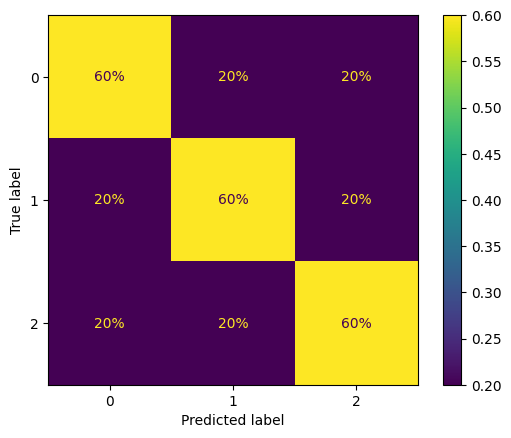

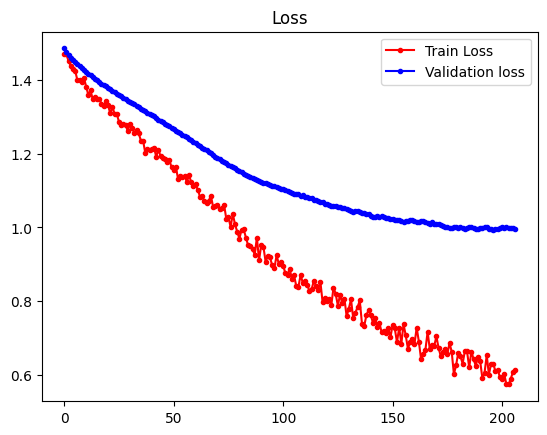

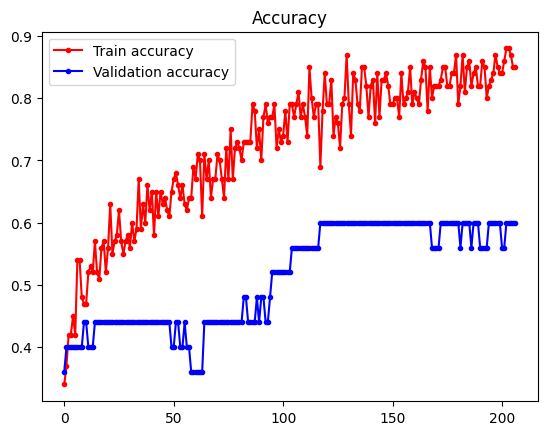

In [54]:
reset_weights(model3_c_s)
history2_s=model3_c_s.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, batch_size = 3, validation_data = (X_test, y_test), callbacks = [EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
acc_3_SNN_test = evaluate_model(model3_c_s, history2_s, X_test, y_test)

# 2 Class

## C-DNN

In [55]:

target = 'pond_2'
df_val_train, df_test = train_test_split(df, test_size=0.2, random_state=111, stratify=df[target])
X_train = df_val_train[predictors].values.reshape(-1, len(predictors), 1)
X_test = df_test[predictors].values.reshape(-1, len(predictors), 1)

y_train = df_val_train[target].values
y_train = keras.utils.to_categorical(y_train, num_classes=max(df[target])+1)
y_test = df_test[target].values
y_test = keras.utils.to_categorical(y_test, num_classes=max(df[target])+1)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(100, 126, 1) (100, 2) (25, 126, 1) (25, 2)


In [31]:
input_data = Input(shape=(126,1))
conv_output = Conv1D(filters=2, kernel_size=25, activation='relu', input_shape=(126,1), kernel_regularizer=keras.regularizers.l2(0.01))(input_data)
conv_output = Conv1D(filters=1, kernel_size=4, activation='relu', kernel_regularizer=l2(0.01))(conv_output)
conv_features = MaxPooling1D(pool_size=4)(conv_output)
output = Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01))(conv_features)
output = Flatten()(output)
output = Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01))(output)
output = Dropout(rate=0.25)(output)
output = Dense(16, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01))(output)
output = Dense(2, activation='softmax')(output)


model2_c = keras.Model(inputs=input_data, outputs=output)
optimizer = keras.optimizers.Adam(learning_rate=0.001)
model2_c.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
model2_c.summary()

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 126, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_8 (Conv1D)               │ (None, 102, 2)         │            52 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 99, 1)          │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 24, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 24, 64)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 32)             │        49,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,935 (195.06 KB)

 Trainable params: 49,935 (195.06 KB)

 Non-trainable params: 0 (0.00 B)

Number of classes: 2
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.8500 - loss: 1.0518
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
predicted classes:       [0 0 1 1 1 0 1 1 1 0 0 0 1 0 0 1 1 0 0 0]
true validation classes: [1 0 1 1 1 0 1 0 1 0 0 0 0 0 0 1 1 0 0 0]
mean confidence score: 189649.5151, sd confidence score: 613782.1159
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8500 - loss: 0.7778
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
predicted classes:       [0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 1 0 1 0 1]
true validation classes: [0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0]
mean confidence score: 1119177.406, sd confidence score: 4831934.092
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8000 - loss: 0.7860
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
predicted classes:       [0 1 0 1 1 0 0 0 0 1 0 0 0 0 1 1 1 1 1 1]
true validation classes: [0 1 0 0 1 1 0 0 0 1 0 0 0 1 0 1 1 1 1 1]
mean confidence score: 8609.6645, sd confi

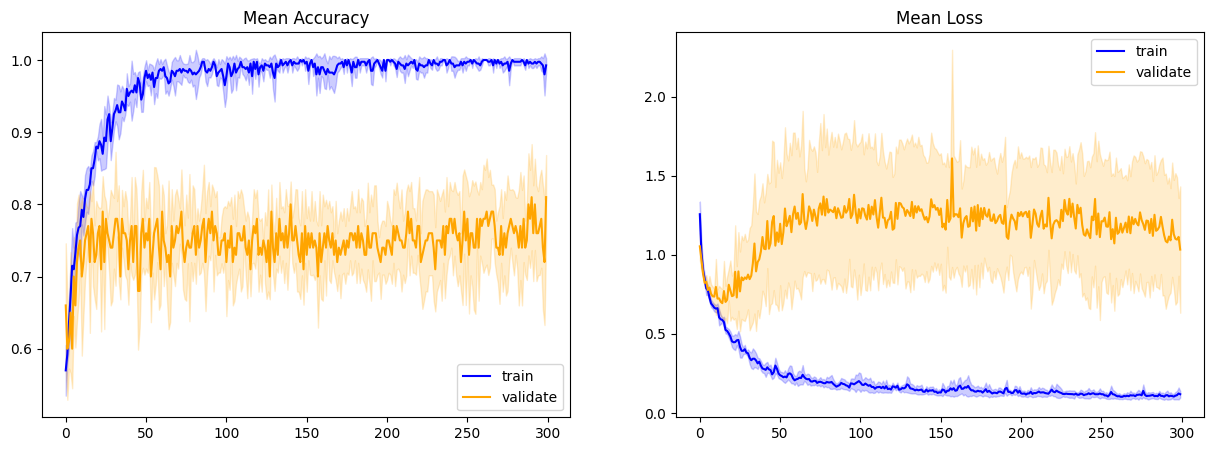

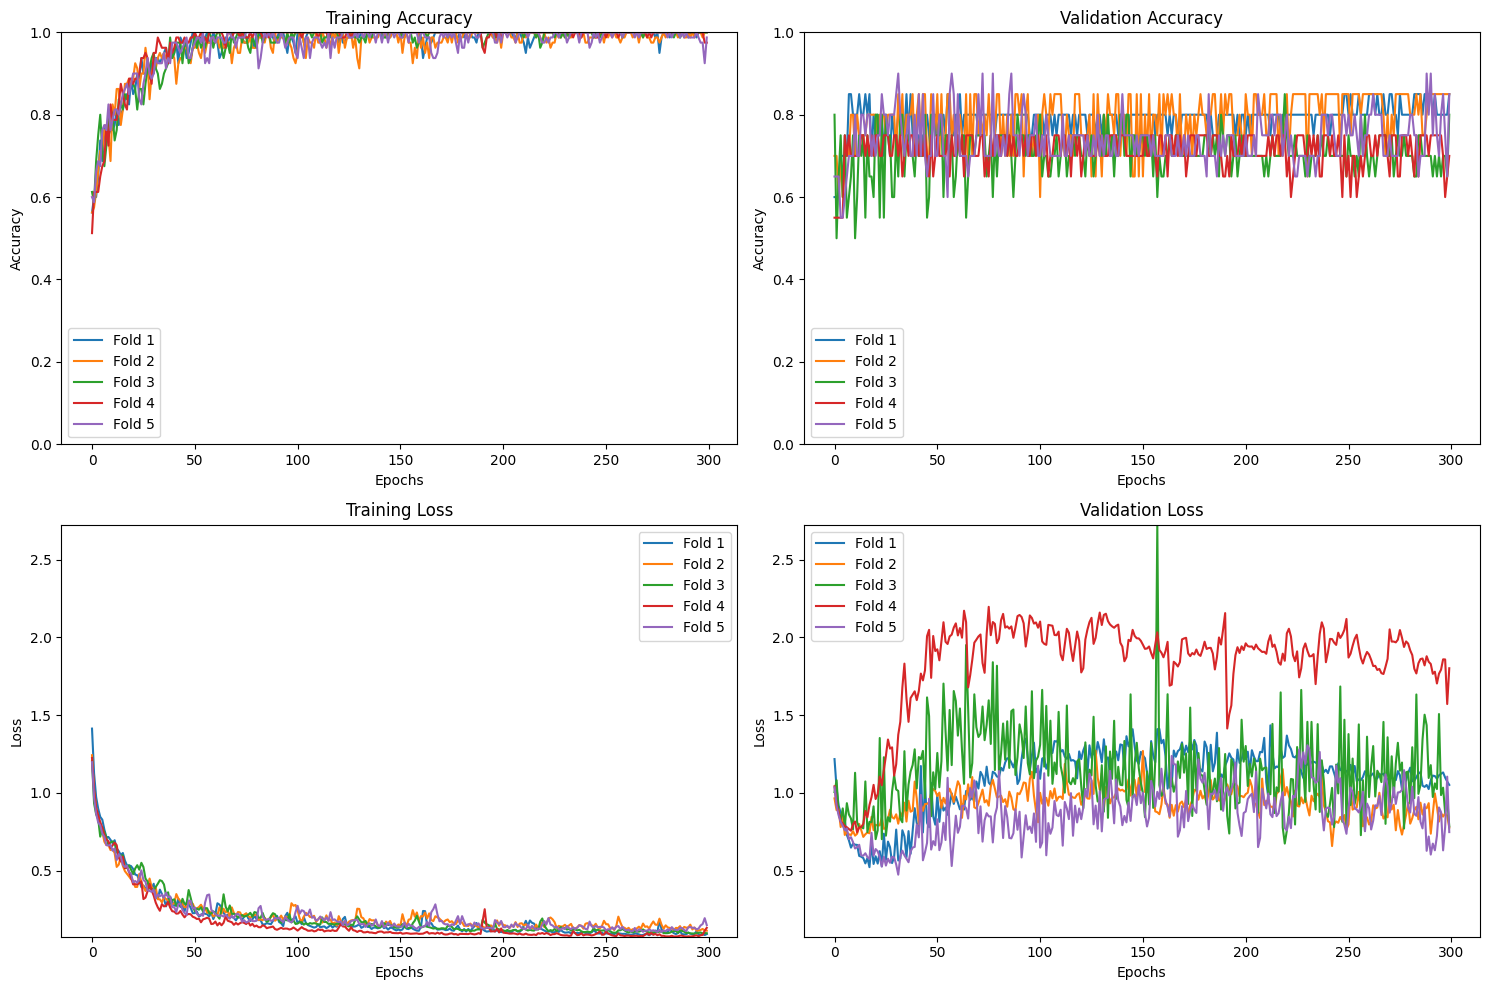

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
predicted classes:       [0 0 0 0 0 0 1 0 1 0 1 1 1 0 0 1 0 0 0 0]
true validation classes: [0 0 0 1 0 0 1 0 1 0 1 1 1 0 1 0 0 0 0 0]


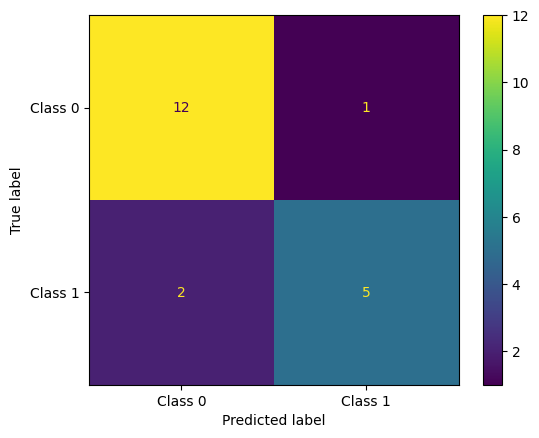

In [32]:
mean_acc_DNN_2_val, sd_acc_DNN_2_val = crossvalidate(df_val_train, model2_c, predictors, 'pond_2',kf,300,True)

Epoch 1/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6057 - loss: 1.2125 - val_accuracy: 0.7200 - val_loss: 0.8677
Epoch 2/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6702 - loss: 0.8925 - val_accuracy: 0.6000 - val_loss: 0.8673
Epoch 3/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6545 - loss: 0.8331 - val_accuracy: 0.6000 - val_loss: 0.7826
Epoch 4/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6677 - loss: 0.7476 - val_accuracy: 0.7600 - val_loss: 0.7389
Epoch 5/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7041 - loss: 0.7066 - val_accuracy: 0.7200 - val_loss: 0.7201
Epoch 6/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6937 - loss: 0.7388 - val_accuracy: 0.8000 - val_loss: 0.6881
Epoch 7/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7628 - loss: 0.6687 - val_accuracy: 0.6400 - val_loss: 0.7230
Epoch 8/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7669 - loss: 0.6714 - val_accuracy: 0.7200 - v

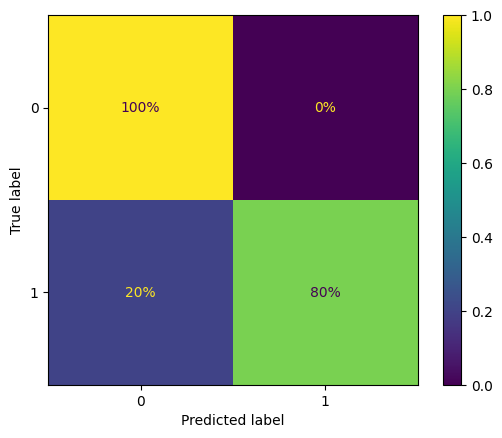

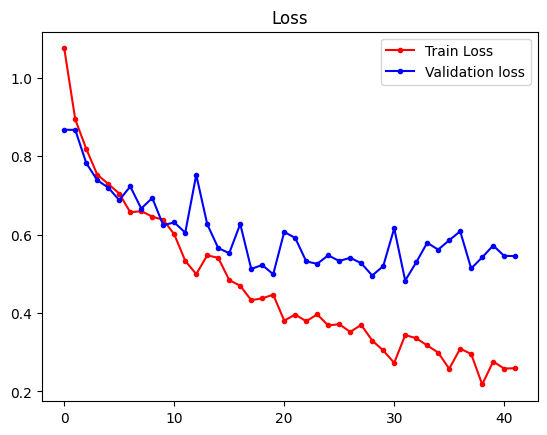

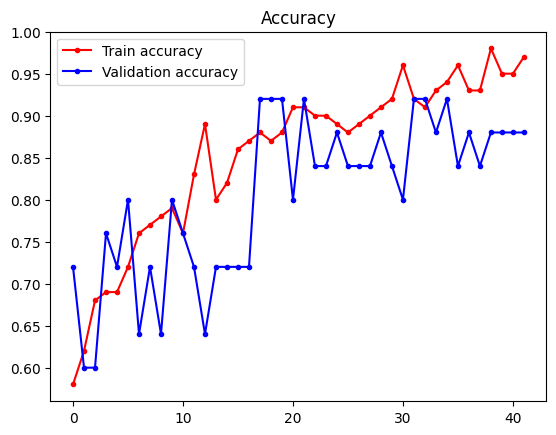

In [33]:
reset_weights(model2_c)
history3=model2_c.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, batch_size = 3, validation_data = (X_test, y_test), callbacks = [EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
acc_2_DNN_test = evaluate_model(model2_c, history3, X_test, y_test)

## XGB

In [34]:
feature_extractor_5_c = keras.Model(
    inputs=model5_c.input,
    outputs=Flatten()(model5_c.get_layer("max_pooling1d").output)
)


conv_data_test = feature_extractor_5_c.predict(X_test)
conv_data_train = feature_extractor_5_c.predict(X_train)

xgb_df_test = pd.DataFrame(conv_data_test)
column_names = xgb_df_test.columns.tolist()
column_names = [str(i) for i in column_names]
xgb_df_test.columns = column_names
xgb_df_test[target] = df_test[target].values

xgb_df_train = pd.DataFrame(conv_data_train)
xgb_df_train.columns = column_names
xgb_df_train[target] = df_val_train[target].values


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


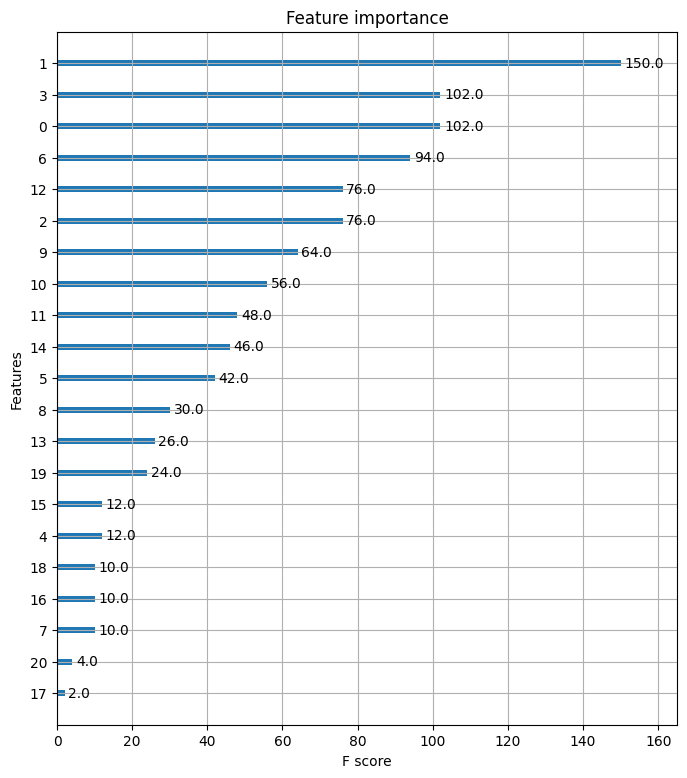

Accuracy0.84
true: [1 1 1 0 1 1 1 1 0 0 1 0 0 0 0 0 0 0 1 1 0 0 0 0 0]
predicted: [1. 0. 1. 0. 1. 1. 1. 1. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.
 0.]


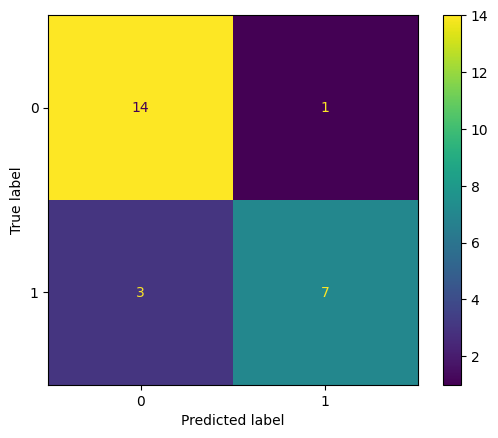

In [35]:
dtrain = xgb.DMatrix(xgb_df_train[column_names].values, label=xgb_df_train[target].values, feature_names=column_names)  
dtest = xgb.DMatrix(xgb_df_test[column_names].values, label=xgb_df_test[target].values, feature_names=column_names)
params = {
    'objective': 'multi:softmax',
    'num_class': 2,
    'max_depth': 3, 
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)

fig, ax = plt.subplots(figsize=(8, 9))  
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")
acc_XGB_2_test = xgb_acc
cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

## C-SNN

In [56]:
model2_c_s = keras.Sequential([
    Conv1D(filters=2, kernel_size=25, activation='relu', input_shape=(126,1), kernel_regularizer=keras.regularizers.l2(0.01)),
    Conv1D(filters=1, kernel_size=4, activation='relu', kernel_regularizer=l2(0.01)),
    MaxPooling1D(pool_size=4),
    Flatten(),
    Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01)),
    Dropout(rate=0.25),
    Dense(2, activation='softmax')
])
model2_c_s.summary()


loss = "categorical_crossentropy"
metrics = ["accuracy"]
optimizer = keras.optimizers.Adam(learning_rate = 0.0001)

model2_c_s.compile(optimizer = optimizer, loss = loss, metrics=metrics)

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_18 (Conv1D)              │ (None, 102, 2)         │            52 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_19 (Conv1D)              │ (None, 99, 1)          │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_9 (MaxPooling1D)  │ (None, 24, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_12 (Flatten)            │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 64)             │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,791 (7.00 KB)

 Trainable params: 1,791 (7.00 KB)

 Non-trainable params: 0 (0.00 B)

Number of classes: 2
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 300ms/step - accuracy: 0.7500 - loss: 0.4697
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
predicted classes:       [1 0 0 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 0 0]
true validation classes: [1 0 1 1 1 0 1 0 1 0 0 0 0 0 0 1 1 0 0 0]
mean confidence score: 9.0267, sd confidence score: 11.042
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7500 - loss: 0.7085
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
predicted classes:       [0 0 1 1 1 0 0 0 1 0 0 0 0 0 0 1 0 1 0 1]
true validation classes: [0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0]
mean confidence score: 10.2839, sd confidence score: 20.1087
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6500 - loss: 0.8370
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
predicted classes:       [0 1 0 1 0 1 0 0 0 1 0 0 1 0 0 0 0 1 0 1]
true validation classes: [0 1 0 0 1 1 0 0 0 1 0 0 0 1 0 1 1 1 1 1]
mean confidence score: 25.3636, sd confidence score: 40.480

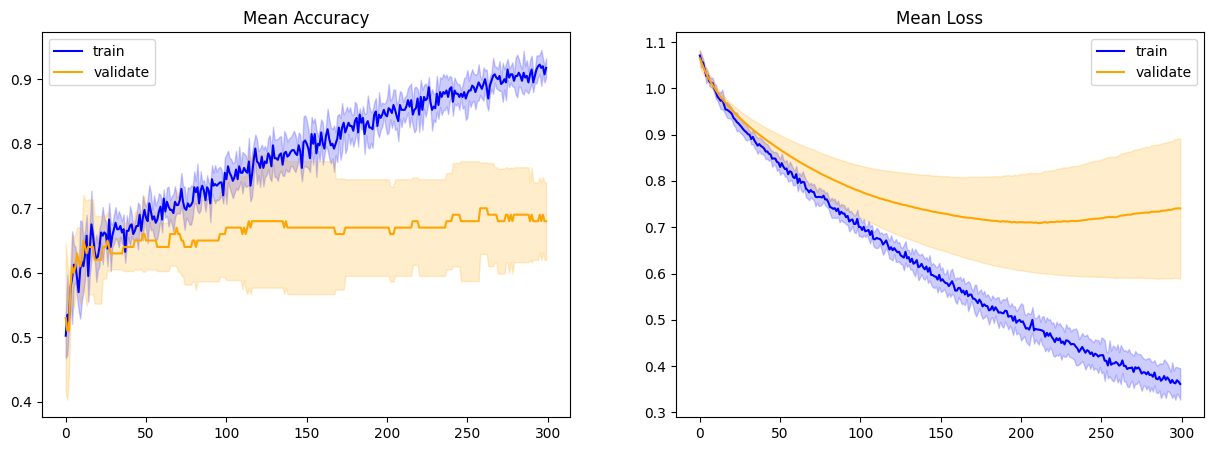

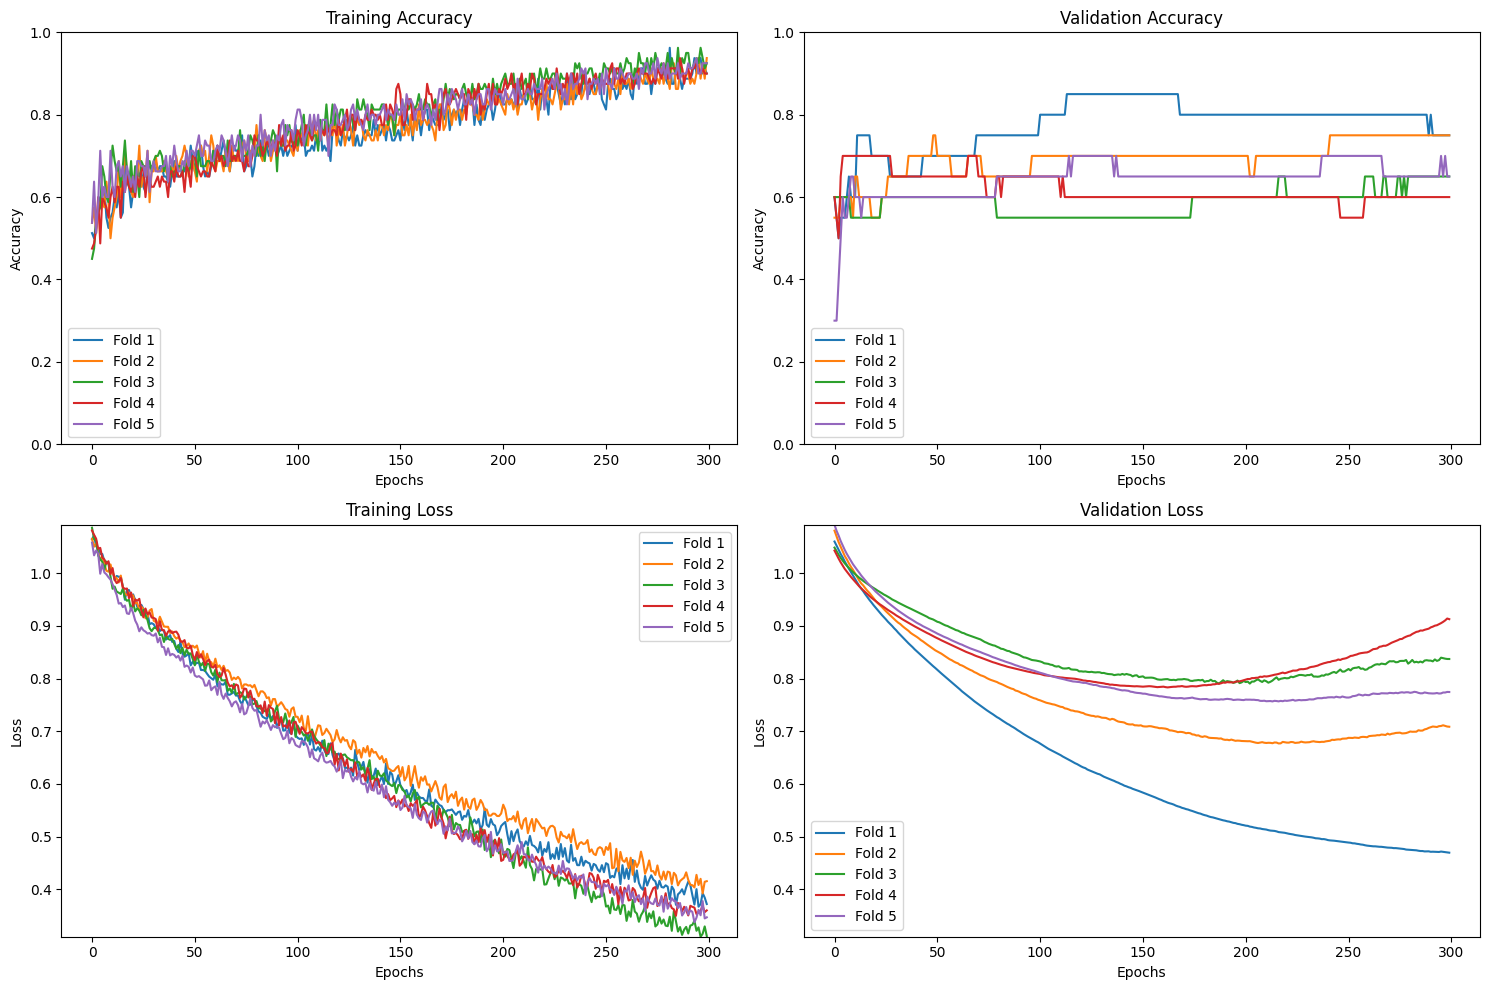

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
predicted classes:       [0 0 1 0 1 0 1 0 1 0 1 1 0 0 0 1 0 1 0 0]
true validation classes: [0 0 0 1 0 0 1 0 1 0 1 1 1 0 1 0 0 0 0 0]


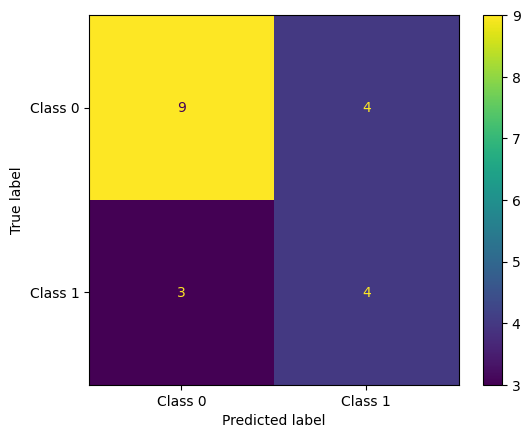

In [57]:
mean_acc_SNN_2_val, sd_acc_SNN_2_val = crossvalidate(df_val_train, model2_c_s, predictors, 'pond_2',kf,300,True)

Epoch 1/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5399 - loss: 1.0715 - val_accuracy: 0.6400 - val_loss: 1.0563
Epoch 2/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7076 - loss: 1.0122 - val_accuracy: 0.5200 - val_loss: 1.0350
Epoch 3/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6250 - loss: 1.0220 - val_accuracy: 0.5200 - val_loss: 1.0179
Epoch 4/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6944 - loss: 1.0079 - val_accuracy: 0.5200 - val_loss: 1.0036
Epoch 5/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5926 - loss: 1.0023 - val_accuracy: 0.5200 - val_loss: 0.9908
Epoch 6/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6250 - loss: 0.9835 - val_accuracy: 0.5600 - val_loss: 0.9796
Epoch 7/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7123 - loss: 0.9581 - val_accuracy: 0.6000 - val_loss: 0.9691
Epoch 8/500
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6049 - loss: 0.9657 - val_accuracy: 0.6400 - v

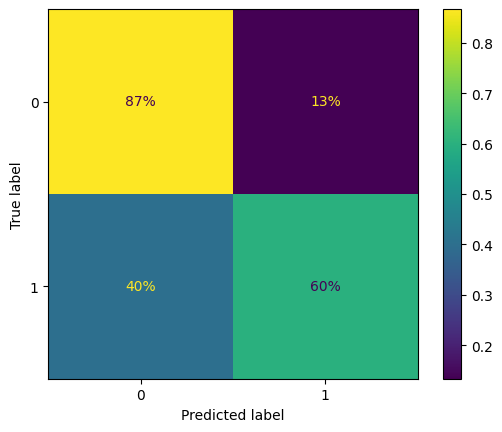

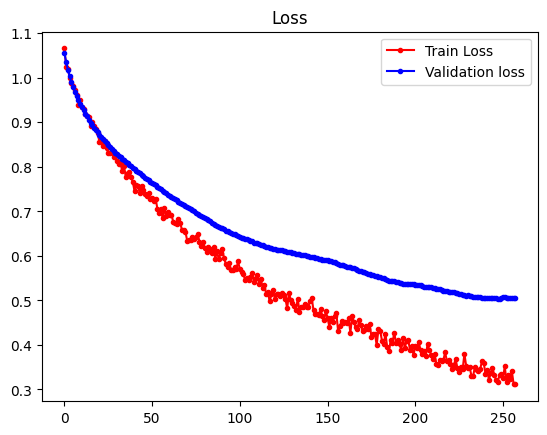

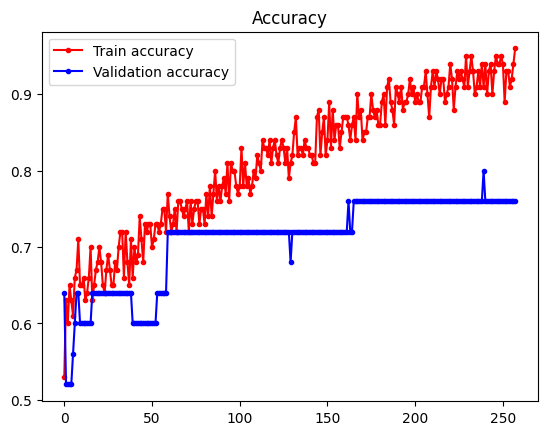

In [58]:
reset_weights(model2_c_s)
history3_s=model2_c_s.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, batch_size = 3, validation_data = (X_test, y_test), callbacks = [EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
acc_2_SNN_test = evaluate_model(model2_c_s, history3_s, X_test, y_test)

# END

In [59]:
print("DNN")
print(f"Accuracy class 5: {round(mean_acc_DNN_5_val,2)}, sd: {round(sd_acc_DNN_5_val,2)}, test: {acc_5_DNN_test}")
print(f"Accuracy class 3: {round(mean_acc_DNN_3_val,2)}, sd: {round(sd_acc_DNN_3_val,2)}, test: {acc_3_DNN_test}")
print(f"Accuracy class 2: {round(mean_acc_DNN_2_val,2)}, sd: {round(sd_acc_DNN_2_val,2)}, test: {acc_2_DNN_test}")
print("SNN")
print(f"Accuracy class 5: {round(mean_acc_SNN_5_val,2)}, sd: {round(sd_acc_SNN_5_val,2)}, test: {acc_5_SNN_test}")
print(f"Accuracy class 3: {round(mean_acc_SNN_3_val,2)}, sd: {round(sd_acc_SNN_3_val,2)}, test: {acc_3_SNN_test}")
print(f"Accuracy class 2: {round(mean_acc_SNN_2_val,2)}, sd: {round(sd_acc_SNN_2_val,2)}, test: {acc_2_SNN_test}")
print("XGB")
print(f"Accuracy class 5: {acc_XGB_5_test}")
print(f"Accuracy class 3: {acc_XGB_3_test}")
print(f"Accuracy class 2: {acc_XGB_2_test}")


DNN
Accuracy class 5: 0.52, sd: 0.05, test: 0.5199999809265137
Accuracy class 3: 0.72, sd: 0.02, test: 0.5199999809265137
Accuracy class 2: 0.81, sd: 0.06, test: 0.8799999952316284
SNN
Accuracy class 5: 0.4, sd: 0.14, test: 0.5600000023841858
Accuracy class 3: 0.6, sd: 0.1, test: 0.6000000238418579
Accuracy class 2: 0.68, sd: 0.06, test: 0.7599999904632568
XGB
Accuracy class 5: 0.56
Accuracy class 3: 0.64
Accuracy class 2: 0.84


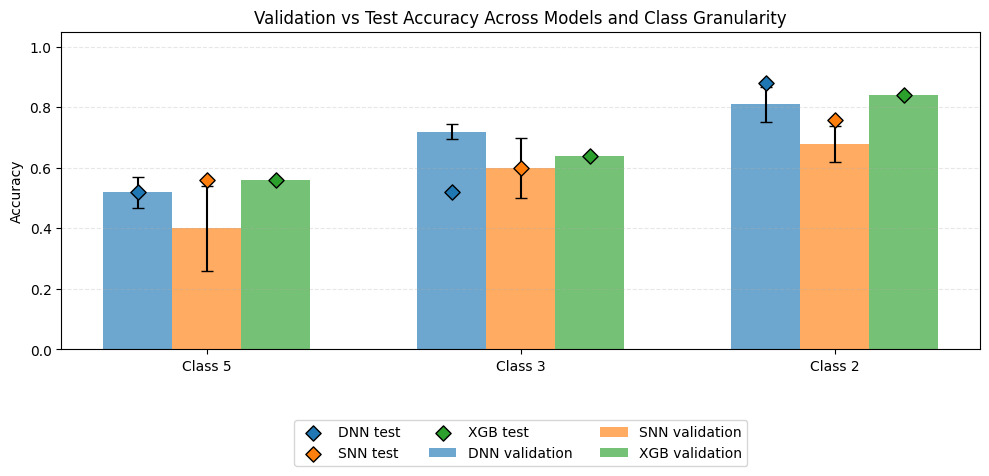

In [60]:
accuracy_rows = [
    ("DNN", "Class 5", mean_acc_DNN_5_val, sd_acc_DNN_5_val, acc_5_DNN_test),
    ("DNN", "Class 3", mean_acc_DNN_3_val, sd_acc_DNN_3_val, acc_3_DNN_test),
    ("DNN", "Class 2", mean_acc_DNN_2_val, sd_acc_DNN_2_val, acc_2_DNN_test),
    ("SNN", "Class 5", mean_acc_SNN_5_val, sd_acc_SNN_5_val, acc_5_SNN_test),
    ("SNN", "Class 3", mean_acc_SNN_3_val, sd_acc_SNN_3_val, acc_3_SNN_test),
    ("SNN", "Class 2", mean_acc_SNN_2_val, sd_acc_SNN_2_val, acc_2_SNN_test),
    ("XGB", "Class 5", acc_XGB_5_test, 0.0, acc_XGB_5_test),
    ("XGB", "Class 3", acc_XGB_3_test, 0.0, acc_XGB_3_test),
    ("XGB", "Class 2", acc_XGB_2_test, 0.0, acc_XGB_2_test),
]

accuracy_df = pd.DataFrame(
    accuracy_rows,
    columns=["Model", "Class", "val_mean", "val_sd", "test_acc"],
)

class_labels = ["Class 5", "Class 3", "Class 2"]
model_order = ["DNN", "SNN", "XGB"]
x_positions = np.arange(len(class_labels))
bar_width = 0.22
palette = {"DNN": "#1f77b4", "SNN": "#ff7f0e", "XGB": "#2ca02c"}

fig, ax = plt.subplots(figsize=(10, 5))
for idx, model in enumerate(model_order):
    subset = accuracy_df[accuracy_df["Model"] == model].set_index("Class").loc[class_labels]
    offsets = x_positions + (idx - (len(model_order) - 1) / 2) * bar_width
    ax.bar(
        offsets,
        subset["val_mean"],
        bar_width,
        yerr=subset["val_sd"],
        capsize=4,
        alpha=0.65,
        color=palette[model],
        label=f"{model} validation",
    )
    ax.scatter(
        offsets,
        subset["test_acc"],
        color=palette[model],
        edgecolors="black",
        marker="D",
        s=60,
        zorder=3,
        label=f"{model} test",
    )

ax.set_xticks(x_positions)
ax.set_xticklabels(class_labels)
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("Validation vs Test Accuracy Across Models and Class Granularity")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(ncol=3, bbox_to_anchor=(0.5, -0.2), loc="upper center")
plt.tight_layout()
plt.show()

In [61]:
resultsdf = pd.DataFrame(accuracy_rows, columns=["Model", "Class", "val_mean", "val_sd", "test_acc"])
print(resultsdf)
resultsdf.to_csv("results\\Gut_2_C_results.csv", index=False)




  Model    Class  val_mean    val_sd  test_acc
0   DNN  Class 5      0.52  0.050990      0.52
1   DNN  Class 3      0.72  0.024495      0.52
2   DNN  Class 2      0.81  0.058310      0.88
3   SNN  Class 5      0.40  0.141421      0.56
4   SNN  Class 3      0.60  0.100000      0.60
5   SNN  Class 2      0.68  0.060000      0.76
6   XGB  Class 5      0.56  0.000000      0.56
7   XGB  Class 3      0.64  0.000000      0.64
8   XGB  Class 2      0.84  0.000000      0.84
